# Lecture 8 notebook: Filters and overlays

Companion to Lecture 8 of *Systematic Trading Notes*. Four filters, one per source of information and one per action,
applied to the same base system and judged by one common test: at equal speed, after costs, and by what they add to
the unfiltered system. Data: the 16 ETFs of Lectures 5 to 9, daily, 2000–2026; FRED series for the 3-month Treasury bill
and the VIX. Every input is lagged by one day, so that no filter uses information it would not have had.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "08-filters-and-overlays" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
C = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")["close"][TICKERS]
r = np.log(C).diff()
vol = r.ewm(span=60, min_periods=60).std()
TARGET = 0.10 / np.sqrt(252)
START = "2001-01-01"
idx = C.index


def fred(name):
    s = pd.read_csv(RAW / f"fred_{name}.csv", parse_dates=["observation_date"], index_col="observation_date").iloc[:, 0]
    return pd.to_numeric(s, errors="coerce").reindex(idx).ffill(limit=30).shift(1)   # known the next day


tbill, vix = fred("DTB3"), fred("VIXCLS")


def run(sig):
    pos = sig * TARGET / vol
    port = (pos.shift(1) * r).mean(axis=1).loc[START:]
    to = pos.diff().abs().mean(axis=1).loc[START:]
    return port, to


def metrics(port, to):
    cum = port.cumsum()
    out = {"turnover per year": 252 * to.mean(), "Sharpe, no costs": np.sqrt(252) * port.mean() / port.std()}
    net = port - to * 5 / 1e4
    out["Sharpe, 5 bp"] = np.sqrt(252) * net.mean() / net.std()
    out["max drawdown %"] = 100 * (cum - cum.cummax()).min()
    return out

## 3. The yardstick: the unfiltered rule at every speed (Table 3.1)

Time-series momentum at several lookbacks. A filter changes how often the system trades, so it must beat this curve
at its own turnover, not just the 12-month rule it was applied to.

In [2]:
sign = {n: np.sign(np.log(C).diff(n)) for n in (42, 63, 126, 189, 252, 378)}
curve = pd.DataFrame({n: metrics(*run(s)) for n, s in sign.items()}).T
curve.index.name = "lookback (days)"
display(curve.round(2))
base_sig = sign[252]
base_port, base_to = run(base_sig)
cs = curve.sort_values("turnover per year")


def on_curve(turnover, col):
    return float(np.interp(turnover, cs["turnover per year"], cs[col]))

,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %
lookback (days),,,,
42,24.44,0.45,0.21,-10.54
63,19.44,0.32,0.14,-11.13
126,13.98,0.53,0.40,-10.53
189,11.00,0.59,0.48,-10.60
252,10.00,0.60,0.51,-13.63
378,8.06,0.46,0.39,-16.85


## 4. Four filters on the 12-month rule (Table 4.1)

| Filter | Source | Action | Rule |
|---|---|---|---|
| Efficiency-ratio gate | Price | Gate | Hold the position only while the asset's 63-day efficiency ratio exceeds a threshold; flat otherwise |
| Correlation scale | Cross-market | Scale | Halve every position while the average pairwise 63-day correlation of the 16 ETFs is above its median to date |
| Zero-rate regime | Macro | Restrict direction | No short positions while the 3-month Treasury bill yields below 0.25% |
| VIX regime | Implied volatility | Switch speed | Use the 3-month signal while the VIX is above its median to date, the 12-month signal otherwise |

In [3]:
lp = np.log(C)
er = (lp.diff(63).abs() / lp.diff().abs().rolling(63).sum()).shift(1)
rho_rows = r.rolling(63).corr()
avg_rho = rho_rows.groupby(level=0).apply(lambda m: (m.values[~np.eye(len(m), dtype=bool)]).mean() if m.notna().values.sum() > 30 else np.nan)
avg_rho = pd.Series(avg_rho, index=idx).shift(1)
rho_med = avg_rho.expanding(252).median()
vix_med = vix.expanding(252).median()

filters = {}
for th in (0.1, 0.2, 0.3):
    filters[f"efficiency-ratio gate, threshold {th}"] = base_sig.where(er > th, 0.0)
scale = pd.Series(np.where(avg_rho > rho_med, 0.5, 1.0), idx)
filters["correlation scale, halve above median"] = base_sig.mul(scale, axis=0)
zero = (tbill < 0.25)
filters["zero-rate regime, no shorts"] = base_sig.where(~(zero.values[:, None] & (base_sig < 0).values), 0.0)
hi_vix = (vix > vix_med)
hv = pd.DataFrame(np.repeat(hi_vix.values[:, None], len(TICKERS), axis=1), index=idx, columns=TICKERS)
filters["VIX regime, fast signal when high"] = sign[63].where(hv, base_sig)

rows = {"unfiltered 12-month rule": {**metrics(base_port, base_to)}}
for k, s in filters.items():
    p, t = run(s)
    m = metrics(p, t)
    m["curve Sharpe at same turnover, no costs"] = on_curve(m["turnover per year"], "Sharpe, no costs")
    m["curve Sharpe at same turnover, 5 bp"] = on_curve(m["turnover per year"], "Sharpe, 5 bp")
    d = pd.concat([p, base_port], axis=1, keys=["f", "b"]).dropna()
    X = np.column_stack([np.ones(len(d)), d.b])
    beta = np.linalg.lstsq(X, d.f, rcond=None)[0]
    e = d.f - X @ beta
    se = np.sqrt(np.diag(e @ e / (len(d) - 2) * np.linalg.inv(X.T @ X)))
    m["correlation with unfiltered"] = d.corr().iloc[0, 1]
    m["alpha over unfiltered, % a year"] = 100 * 252 * beta[0]
    m["t(alpha)"] = beta[0] / se[0]
    rows[k] = m
table = pd.DataFrame(rows).T
pd.set_option("display.width", 250)
display(table.round(2))
print("share of days each filter was active:")
print({"ER>0.2 (avg across assets)": round(float((er > 0.2).loc[START:].mean().mean()), 2),
       "correlation above median": round(float((avg_rho > rho_med).loc[START:].mean()), 2),
       "zero rates": round(float(zero.loc[START:].mean()), 2), "VIX above median": round(float(hi_vix.loc[START:].mean()), 2)})

,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %,"curve Sharpe at same turnover, no costs","curve Sharpe at same turnover, 5 bp",correlation with unfiltered,"alpha over unfiltered, % a year",t(alpha)
unfiltered 12-month rule,10.00,0.60,0.51,-13.63,NaN,NaN,NaN,NaN,NaN
"efficiency-ratio gate, threshold 0.1",20.12,0.43,0.17,-9.38,0.34,0.15,0.85,-0.31,-0.80
"efficiency-ratio gate, threshold 0.2",11.18,0.21,-0.03,-8.47,0.58,0.48,0.61,-0.37,-0.98
"efficiency-ratio gate, threshold 0.3",4.51,-0.16,-0.35,-7.06,0.46,0.39,0.40,-0.45,-2.18
"correlation scale, halve above median",10.36,0.59,0.48,-13.67,0.59,0.50,0.97,0.03,0.13
"zero-rate regime, no shorts",8.85,0.66,0.58,-13.63,0.52,0.44,0.95,0.50,1.51
"VIX regime, fast signal when high",17.78,0.51,0.35,-11.48,0.39,0.22,0.73,0.43,0.57


share of days each filter was active:
{'ER>0.2 (avg across assets)': 0.2, 'correlation above median': 0.28, 'zero rates': 0.35, 'VIX above median': 0.43}


### 4.2 Three more variables: volatility, correlation across baskets, stock-bond correlation (Tables 4.2 and 4.3)

First, does the unfiltered rule perform differently across regimes at all? Each state is measured with data up to
the previous day. Then one filter per variable, built from the hypothesis stated in the lecture.

In [4]:
# regimes, all lagged one day
vol_med = vol.expanding(252).median()
hv_asset = (vol > vol_med).shift(1)                                    # per asset
groups = {"equities": ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ"], "bonds": ["AGG", "TLT"], "commodities": ["GLD", "SLV", "GDX", "USO"]}
bk = pd.DataFrame({g: r[m].mean(axis=1, skipna=True) for g, m in groups.items()})
pairs = [("equities", "bonds"), ("equities", "commodities"), ("bonds", "commodities")]
xcorr = pd.concat([bk[a].rolling(63).corr(bk[b]) for a, b in pairs], axis=1).mean(axis=1).shift(1)
xcorr_med = xcorr.expanding(252).median()
sb = r["SPY"].rolling(126).corr(r["TLT"]).shift(1)

# per-asset contribution of the unfiltered rule, to condition on asset-level states
contrib = (base_sig * TARGET / vol).shift(1) * r


def cond_sharpe(mask_rows=None, mask_cells=None):
    if mask_cells is not None:
        x = contrib.where(mask_cells).loc[START:]
        port = x.mean(axis=1).dropna()
    else:
        port = contrib.loc[START:].mean(axis=1)[mask_rows.loc[START:].fillna(False)]
    return np.sqrt(252) * port.mean() / port.std(), len(port)


rows = {}
for lab, cells in (("asset volatility above its median", hv_asset == True), ("asset volatility below its median", hv_asset == False)):
    sr, n = cond_sharpe(mask_cells=cells); rows[lab] = {"Sharpe ratio of the unfiltered rule": sr, "days": n}
for lab, m in (("cross-basket correlation above its median", xcorr > xcorr_med), ("cross-basket correlation below its median", xcorr <= xcorr_med),
               ("stock-bond correlation positive", sb > 0), ("stock-bond correlation negative", sb <= 0)):
    sr, n = cond_sharpe(mask_rows=m); rows[lab] = {"Sharpe ratio of the unfiltered rule": sr, "days": n}
regimes = pd.DataFrame(rows).T
display(regimes.round(2))

more = {}
hv_cells = pd.DataFrame(hv_asset.values, index=idx, columns=TICKERS).fillna(False).astype(bool)
more["volatility gate: trade only when asset volatility is high"] = base_sig.where(hv_cells, 0.0)
more["volatility gate: trade only when asset volatility is low"] = base_sig.where(~hv_cells, 0.0)
more["cross-basket correlation: 1.5x above median, 0.5x below"] = base_sig.mul(pd.Series(np.where(xcorr > xcorr_med, 1.5, 0.5), idx), axis=0)
more["cross-basket correlation, reversed after seeing the data: 0.5x above median, 1.5x below"] = base_sig.mul(pd.Series(np.where(xcorr > xcorr_med, 0.5, 1.5), idx), axis=0)
more["stock-bond correlation: 1.5x when positive, 0.5x when negative"] = base_sig.mul(pd.Series(np.where(sb > 0, 1.5, 0.5), idx), axis=0)
rows = {}
for k, sgl in more.items():
    p_, t_ = run(sgl)
    m = metrics(p_, t_)
    m["curve Sharpe at same turnover, no costs"] = on_curve(m["turnover per year"], "Sharpe, no costs")
    d = pd.concat([p_, base_port], axis=1, keys=["f", "b"]).dropna()
    X = np.column_stack([np.ones(len(d)), d.b])
    beta = np.linalg.lstsq(X, d.f, rcond=None)[0]
    e = d.f - X @ beta
    se = np.sqrt(np.diag(e @ e / (len(d) - 2) * np.linalg.inv(X.T @ X)))
    m["correlation with unfiltered"] = d.corr().iloc[0, 1]
    m["alpha over unfiltered, % a year"] = 100 * 252 * beta[0]
    m["t(alpha)"] = beta[0] / se[0]
    rows[k] = m
more_table = pd.DataFrame(rows).T
display(more_table.round(2))
print("share of days positive stock-bond correlation:", round(float((sb > 0).loc[START:].mean()), 2))

,Sharpe ratio of the unfiltered rule,days
asset volatility above its median,0.59,5539.0
asset volatility below its median,0.65,5916.0
cross-basket correlation above its median,0.51,3691.0
cross-basket correlation below its median,0.88,2088.0
stock-bond correlation positive,0.97,1335.0
stock-bond correlation negative,0.45,4632.0


,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %,"curve Sharpe at same turnover, no costs",correlation with unfiltered,"alpha over unfiltered, % a year",t(alpha)
volatility gate: trade only when asset volatility is high,5.69,0.21,0.11,-11.93,0.46,0.69,-0.61,-1.45
volatility gate: trade only when asset volatility is low,9.88,0.65,0.53,-12.06,0.59,0.85,0.59,1.37
"cross-basket correlation: 1.5x above median, 0.5x below",15.37,0.52,0.40,-17.85,0.48,0.90,-0.12,-0.22
"cross-basket correlation, reversed after seeing the data: 0.5x above median, 1.5x below",13.05,0.55,0.44,-19.63,0.55,0.89,0.12,0.22
"stock-bond correlation: 1.5x when positive, 0.5x when negative",8.97,0.58,0.48,-13.28,0.53,0.87,0.28,0.65


share of days positive stock-bond correlation: 0.21


### 4.3 How the filter attaches to the signal (Table 4.4)

The same regime can be attached to the trend signal in three ways. A, independent: position = signal x filter every
day, so the filter opens and closes positions itself. B, entry only at the next signal: a new trend position is taken
only if the filter is on on the day the signal turns, and is then held until the signal turns again. C, entry only,
joining the trend: a position is opened when the filter turns on during an existing trend, or when the signal turns
while the filter is on, and is closed only when the signal turns.

In [5]:
def attach(sig, on, mode):
    on = on.reindex(sig.index).fillna(False).astype(bool)
    out = pd.DataFrame(0.0, index=sig.index, columns=sig.columns)
    for t_ in sig.columns:
        s_ = sig[t_].to_numpy(); o_ = on[t_].to_numpy()
        pos, prev, ps = 0.0, 0.0, []
        for v, f in zip(s_, o_):
            if np.isnan(v) or v == 0:
                pos, prev = 0.0, 0.0 if np.isnan(v) else v
                ps.append(pos); continue
            turned = v != prev
            if mode == "A":
                pos = v if f else 0.0
            elif mode == "B":
                if turned:
                    pos = v if f else 0.0
            elif mode == "C":
                if turned:
                    pos = v if f else 0.0
                elif pos == 0 and f:
                    pos = v
            prev = v
            ps.append(pos)
        out[t_] = ps
    return out


def cells(series_or_frame):
    if isinstance(series_or_frame, pd.Series):
        return pd.DataFrame(np.repeat(series_or_frame.values[:, None], len(TICKERS), axis=1), index=idx, columns=TICKERS)
    return series_or_frame


regimes_on = {
    "cross-asset-class correlation low": cells((xcorr <= xcorr_med).fillna(False)),
    "stock-bond correlation positive": cells((sb > 0).fillna(False)),
    "asset volatility low": hv_cells.eq(False),
    "asset volatility high": hv_cells,
    "efficiency ratio above 0.2": (er > 0.2).fillna(False),
}
rows = {}
for name, on in regimes_on.items():
    for mode, lab in (("A", "A independent"), ("B", "B entry at next signal"), ("C", "C entry, joining the trend")):
        p_, t_ = run(attach(base_sig, on, mode))
        m = metrics(p_, t_)
        m["curve Sharpe at same turnover, no costs"] = on_curve(m["turnover per year"], "Sharpe, no costs")
        d = pd.concat([p_, base_port], axis=1, keys=["f", "b"]).dropna()
        X = np.column_stack([np.ones(len(d)), d.b])
        beta = np.linalg.lstsq(X, d.f, rcond=None)[0]
        e = d.f - X @ beta
        se = np.sqrt(np.diag(e @ e / (len(d) - 2) * np.linalg.inv(X.T @ X)))
        m["alpha over unfiltered, % a year"] = 100 * 252 * beta[0]
        m["t(alpha)"] = beta[0] / se[0]
        m["time in market"] = float((attach(base_sig, on, mode).loc[START:] != 0).mean().mean())
        rows[(name, lab)] = m
attach_table = pd.DataFrame(rows).T
display(attach_table[["time in market", "turnover per year", "Sharpe, no costs", "curve Sharpe at same turnover, no costs", "Sharpe, 5 bp", "alpha over unfiltered, % a year", "t(alpha)"]].round(2))

time in market  turnover per year  Sharpe, no costs  curve Sharpe at same turnover, no costs  Sharpe, 5 bp  alpha over unfiltered, % a year  t(alpha)
cross-asset-class correlation low A independent                         0.32               7.20              0.44                                     0.46          0.31                             0.38      0.80
                                  B entry at next signal                0.35               3.13              0.43                                     0.46          0.37                             0.19      0.46
                                  C entry, joining the trend            0.65               4.74              0.58                                     0.46          0.52                             0.37      0.78
stock-bond correlation positive   A independent                         0.19               3.87              0.36                                     0.46          0.28                             0.22      0.54
                                  B entry at next signal                0.17               2.06              0.35                                     0.46          0.29                             0.15      0.44
                                  C entry, joining the trend            0.37               3.08              0.50                                     0.46          0.46                             0.39      0.76
asset volatility low              A independent                         0.52               9.69              0.65                                     0.58          0.52                             0.56      1.36
                                  B entry at next signal                0.51               6.61              0.59                                     0.46          0.50                             0.29      0.80
                                  C entry, joining the trend            0.72               7.81              0.58                                     0.46          0.50                             0.10      0.31
asset volatility high             A independent                         0.38               5.69              0.21                                     0.46          0.11                            -0.61     -1.45
                                  B entry at next signal                0.39               3.23              0.34                                     0.46          0.29                            -0.33     -0.90
                                  C entry, joining the trend            0.66               4.50              0.39                                     0.46          0.34                            -0.64     -1.86
efficiency ratio above 0.2        A independent                         0.20              11.10              0.22                                     0.58         -0.01                            -0.33     -0.90
                                  B entry at next signal                0.16               1.44              0.35                                     0.46          0.31                            -0.05     -0.19
                                  C entry, joining the trend            0.74               4.57              0.51                                     0.46          0.46                            -0.36     -1.50

### 4.4 Curves of filters, not single points (chart G.5)

Each filter is swept over its threshold, as each rule was swept over its speed in Lecture 6: a filter is judged by its
whole curve, not by its best point. Gates use attachment C.

In [6]:
def attach_vec(sig, on, mode="C"):
    # vectorised across assets: loop over days only
    S = sig.to_numpy(); O = on.reindex(sig.index).fillna(False).to_numpy(dtype=bool)
    if O.ndim == 1:
        O = np.repeat(O[:, None], S.shape[1], axis=1)
    pos = np.zeros(S.shape[1]); prev = np.zeros(S.shape[1]); out = np.zeros_like(S)
    for i in range(S.shape[0]):
        v = np.nan_to_num(S[i]); f = O[i]
        turned = v != prev
        if mode == "A":
            pos = np.where(f, v, 0.0)
        else:
            pos = np.where(turned, np.where(f, v, 0.0), pos)
            if mode == "C":
                pos = np.where((~turned) & (pos == 0) & f, v, pos)
        pos = np.where(v == 0, 0.0, pos)
        prev = v; out[i] = pos
    return pd.DataFrame(out, index=sig.index, columns=sig.columns)


sweeps = {}
sweeps["efficiency-ratio gate (C)"] = {th: (er > th) for th in (0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4)}
sweeps["cross-asset-class correlation low (C)"] = {q: (xcorr <= xcorr.expanding(252).quantile(q)) for q in (0.3, 0.4, 0.5, 0.6, 0.7)}
sweeps["stock-bond correlation above threshold (C)"] = {c_: (sb > c_) for c_ in (-0.3, -0.15, 0.0, 0.15, 0.3)}
curve_rows = []
for fam, d in sweeps.items():
    for prm, on in d.items():
        p_, t_ = run(attach_vec(base_sig, on, "C"))
        m = metrics(p_, t_)
        curve_rows.append({"filter": fam, "parameter": prm, **m})
for q in (0.3, 0.4, 0.5, 0.6, 0.7):
    hv_q = pd.DataFrame(np.repeat((vix > vix.expanding(252).quantile(q)).values[:, None], len(TICKERS), axis=1), index=idx, columns=TICKERS)
    p_, t_ = run(sign[63].where(hv_q, base_sig))
    curve_rows.append({"filter": "VIX speed switch", "parameter": q, **metrics(p_, t_)})
fcurves = pd.DataFrame(curve_rows)
display(fcurves.round(2))

,filter,parameter,turnover per year,"Sharpe, no costs","Sharpe, 5 bp",max drawdown %
0,efficiency-ratio gate (C),0.05,8.92,0.58,0.50,-12.92
1,efficiency-ratio gate (C),0.10,7.50,0.55,0.48,-11.99
2,efficiency-ratio gate (C),0.15,5.90,0.51,0.46,-11.84
3,efficiency-ratio gate (C),0.20,4.57,0.51,0.46,-12.01
4,efficiency-ratio gate (C),0.25,3.52,0.53,0.49,-11.18
5,efficiency-ratio gate (C),0.30,2.73,0.45,0.42,-10.47
6,efficiency-ratio gate (C),0.40,1.13,0.27,0.24,-10.46
7,cross-asset-class correlation low (C),0.30,2.20,0.33,0.30,-9.25
8,cross-asset-class correlation low (C),0.40,3.60,0.58,0.54,-8.84
9,cross-asset-class correlation low (C),0.50,4.74,0.58,0.52,-10.72


### 4.5 A fair yardstick for a filter that leaves the market: the random filter (Table 4.5)

For two examples: switch the same rule on and off at random, with the same share of time on and the same average
length of spells as the real filter, attached the same way (C). 200 random filters each. The real filter carries
information only if it beats most of them.

In [7]:
rng = np.random.default_rng(8)


def spells(on):
    o = on.loc[START:].fillna(False).astype(int).to_numpy()
    p_on = o.mean()
    switches = max(1, int(np.abs(np.diff(o)).sum()))
    return p_on, len(o) / switches


def random_regime(p_on, mean_spell, n):
    # two-state Markov chain with the same share of time on and average spell length
    a = 1 / mean_spell                     # leave probability, roughly
    p_off_to_on = a * p_on / (1 - p_on) if p_on < 1 else 1.0
    state = rng.random() < p_on; out = np.empty(n, dtype=bool)
    for i in range(n):
        out[i] = state
        state = (rng.random() > a) if state else (rng.random() < p_off_to_on)
    return out


rand_rows = {}
rand_dist = {}
for name, on in (("cross-asset-class correlation low", (xcorr <= xcorr_med)), ("stock-bond correlation positive", (sb > 0))):
    p_on, L = spells(on)
    real_p, real_t = run(attach_vec(base_sig, on, "C"))
    real_sr = np.sqrt(252) * real_p.mean() / real_p.std()
    sims = []
    for k in range(200):
        rr = pd.Series(random_regime(p_on, L, len(idx)), idx)
        pp, tt = run(attach_vec(base_sig, rr, "C"))
        sims.append(np.sqrt(252) * pp.mean() / pp.std())
    sims = np.array(sims)
    rand_dist[name] = sims
    rand_rows[name] = {"share of time on": p_on, "average spell, days": L, "real filter Sharpe": real_sr,
                       "random filters: median Sharpe": np.median(sims), "random 95th percentile": np.percentile(sims, 95),
                       "share of random filters beaten": (sims < real_sr).mean()}
display(pd.DataFrame(rand_rows).T.round(2))

,share of time on,"average spell, days",real filter Sharpe,random filters: median Sharpe,random 95th percentile,share of random filters beaten
cross-asset-class correlation low,0.32,40.54,0.58,0.50,0.60,0.88
stock-bond correlation positive,0.21,99.78,0.50,0.38,0.55,0.88


### 4.6 Confirmation: the candidate out of sample (Table 4.6)

The cross-asset-class correlation pattern was found on 2006–2026. Here it is chosen on 2006–2015 only, the best
threshold picked there, and applied unchanged to 2016–2026.

In [8]:
IS, OOS = ("2006-01-01", "2015-12-31"), ("2016-01-01", None)


def sr(x):
    return np.sqrt(252) * x.mean() / x.std()


rows = {}
for q in (0.3, 0.4, 0.5, 0.6, 0.7):
    on = (xcorr <= xcorr.expanding(252).quantile(q))
    p_, _ = run(attach_vec(base_sig, on, "C"))
    rows[q] = {"Sharpe 2006-2015": sr(p_.loc[IS[0]:IS[1]]), "Sharpe 2016-2026": sr(p_.loc[OOS[0]:])}
oos = pd.DataFrame(rows).T
oos.index.name = "threshold (quantile of correlation to date)"
best_q = oos["Sharpe 2006-2015"].idxmax()
display(oos.round(2))
print(f"unfiltered: 2006-2015 Sharpe {sr(base_port.loc[IS[0]:IS[1]]):.2f}, 2016-2026 Sharpe {sr(base_port.loc[OOS[0]:]):.2f}")
print(f"threshold chosen in sample: {best_q}; its out-of-sample Sharpe {oos.loc[best_q, 'Sharpe 2016-2026']:.2f}")
low = (xcorr <= xcorr_med)
for lab, (a_, b_) in (("2006-2015", IS), ("2016-2026", OOS)):
    pr = contrib.loc[a_:b_].mean(axis=1)
    m_ = low.loc[a_:b_].fillna(False)
    print(f"{lab}: unfiltered Sharpe when correlation low {sr(pr[m_]):.2f}, when high {sr(pr[~m_]):.2f}")

,Sharpe 2006-2015,Sharpe 2016-2026
threshold (quantile of correlation to date),,
0.3,0.42,0.32
0.4,0.59,0.56
0.5,0.66,0.43
0.6,0.68,0.37
0.7,0.67,0.39


unfiltered: 2006-2015 Sharpe 0.64, 2016-2026 Sharpe 0.40
threshold chosen in sample: 0.6; its out-of-sample Sharpe 0.37
2006-2015: unfiltered Sharpe when correlation low 0.87, when high 0.37
2016-2026: unfiltered Sharpe when correlation low 0.56, when high 0.36


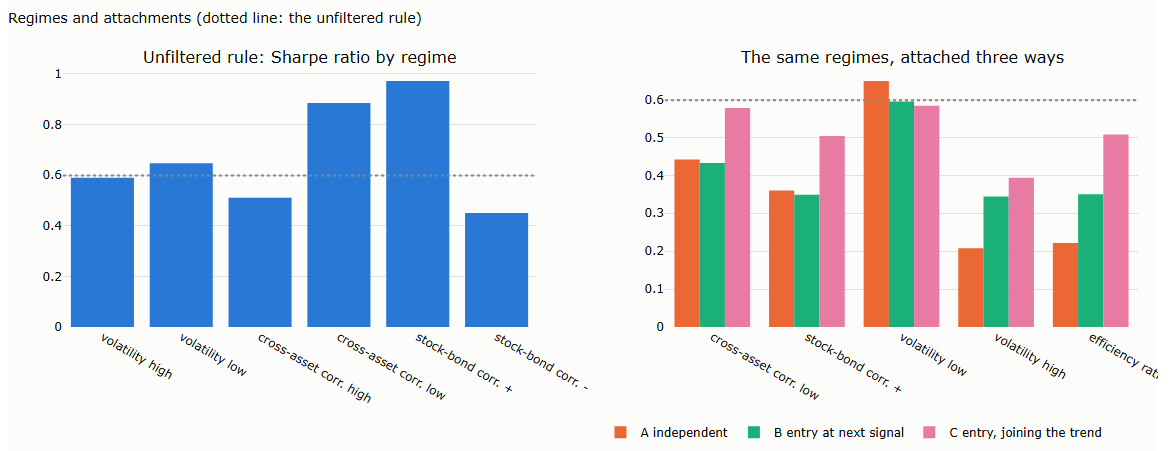

In [9]:
# chart G.3: performance by regime, and the three attachments
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12, subplot_titles=("Unfiltered rule: Sharpe ratio by regime", "The same regimes, attached three ways"))
lab_map = {"asset volatility above its median": "volatility high", "asset volatility below its median": "volatility low",
           "cross-basket correlation above its median": "cross-asset corr. high", "cross-basket correlation below its median": "cross-asset corr. low",
           "stock-bond correlation positive": "stock-bond corr. +", "stock-bond correlation negative": "stock-bond corr. -"}
fig.add_bar(x=[lab_map[k] for k in regimes.index], y=regimes["Sharpe ratio of the unfiltered rule"], marker_color=SERIES[0], showlegend=False, row=1, col=1)
fig.add_hline(y=float(np.sqrt(252) * base_port.mean() / base_port.std()), line=dict(color=MUTED, dash="dot"), row=1, col=1)
for j, mode_lab in enumerate(["A independent", "B entry at next signal", "C entry, joining the trend"]):
    sub = attach_table.xs(mode_lab, level=1)
    short = {"cross-asset-class correlation low": "cross-asset corr. low", "stock-bond correlation positive": "stock-bond corr. +", "asset volatility low": "volatility low", "asset volatility high": "volatility high", "efficiency ratio above 0.2": "efficiency ratio > 0.2"}
    fig.add_bar(x=[short[k] for k in sub.index], y=sub["Sharpe, no costs"], name=mode_lab, marker_color=SERIES[j + 1], row=1, col=2)
fig.add_hline(y=float(np.sqrt(252) * base_port.mean() / base_port.std()), line=dict(color=MUTED, dash="dot"), row=1, col=2)
fig.update_layout(title="Regimes and attachments (dotted line: the unfiltered rule)", barmode="group", height=480, width=1150, margin=dict(t=90, b=120),
                  legend=dict(orientation="h", y=-0.35, x=0.5))
save_figure(fig, "08_03_regimes_attachments", FIG)
fig

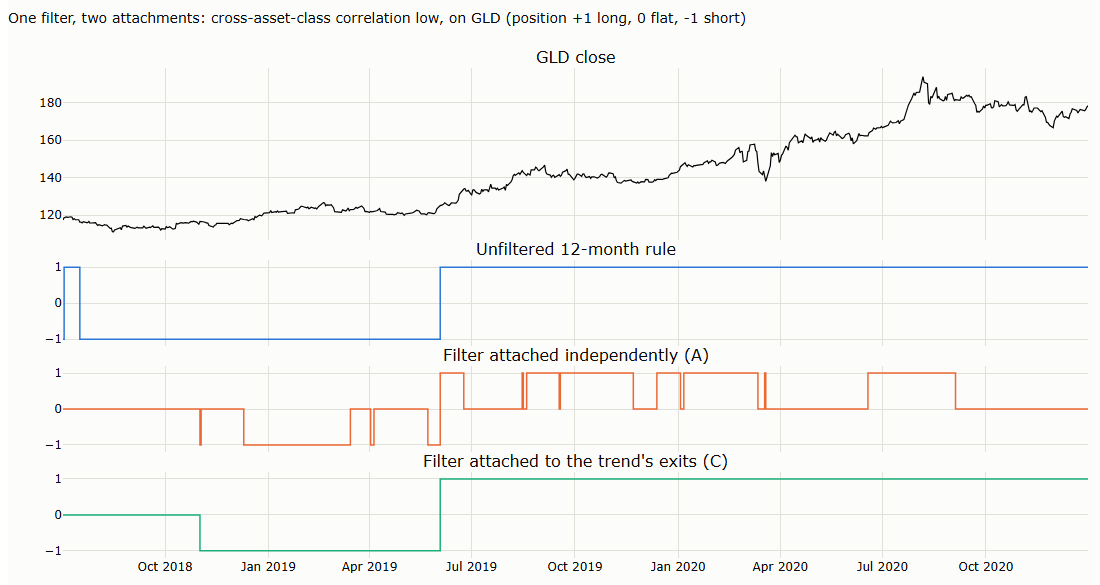

In [10]:
# chart G.4: the same filter attached two ways, on gold
asset, a0, a1 = "GLD", "2018-07-01", "2020-12-31"
on_cells = cells((xcorr <= xcorr_med).fillna(False))
posA = attach_vec(base_sig, on_cells, "A")[asset].loc[a0:a1]
posC = attach_vec(base_sig, on_cells, "C")[asset].loc[a0:a1]
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.04, row_heights=[0.4, 0.2, 0.2, 0.2],
                    subplot_titles=(f"{asset} close", "Unfiltered 12-month rule", "Filter attached independently (A)", "Filter attached to the trend's exits (C)"))
fig.add_scatter(x=C[asset].loc[a0:a1].index, y=C[asset].loc[a0:a1], mode="lines", line=dict(color="black", width=1.2), showlegend=False, row=1, col=1)
for rr_, ser in ((2, base_sig[asset].loc[a0:a1]), (3, posA), (4, posC)):
    fig.add_scatter(x=ser.index, y=ser, mode="lines", line=dict(width=1.5, color=SERIES[rr_ - 2], shape="hv"), showlegend=False, row=rr_, col=1)
    fig.update_yaxes(range=[-1.2, 1.2], tickvals=[-1, 0, 1], row=rr_, col=1)
fig.update_layout(title=f"One filter, two attachments: cross-asset-class correlation low, on {asset} (position +1 long, 0 flat, -1 short)",
                  height=620, width=1100, margin=dict(t=90))
save_figure(fig, "08_04_attachment_example", FIG)
fig

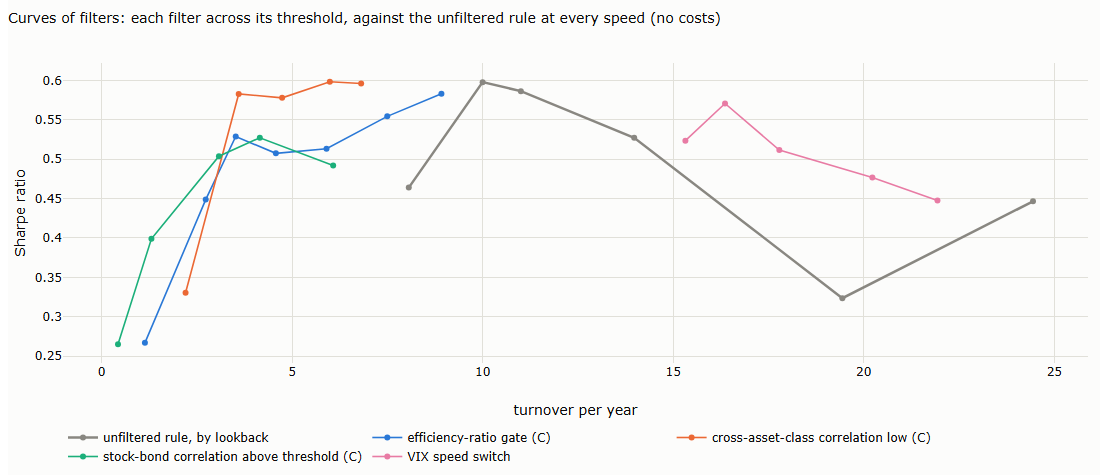

In [11]:
# chart G.5: curves of filters against the speed curve
fig = go.Figure()
fig.add_scatter(x=cs["turnover per year"], y=cs["Sharpe, no costs"], mode="lines+markers", name="unfiltered rule, by lookback", line=dict(color=MUTED, width=2.5))
for j, (fam, g) in enumerate(fcurves.groupby("filter", sort=False)):
    g = g.sort_values("turnover per year")
    fig.add_scatter(x=g["turnover per year"], y=g["Sharpe, no costs"], mode="lines+markers", name=fam, line=dict(width=1.6, color=SERIES[j]),
                    text=[str(v) for v in g["parameter"]], hovertemplate="%{text}: turnover %{x:.1f}, Sharpe %{y:.2f}")
fig.update_layout(title="Curves of filters: each filter across its threshold, against the unfiltered rule at every speed (no costs)",
                  xaxis_title="turnover per year", yaxis_title="Sharpe ratio", height=500, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "08_05_filter_curves", FIG)
fig

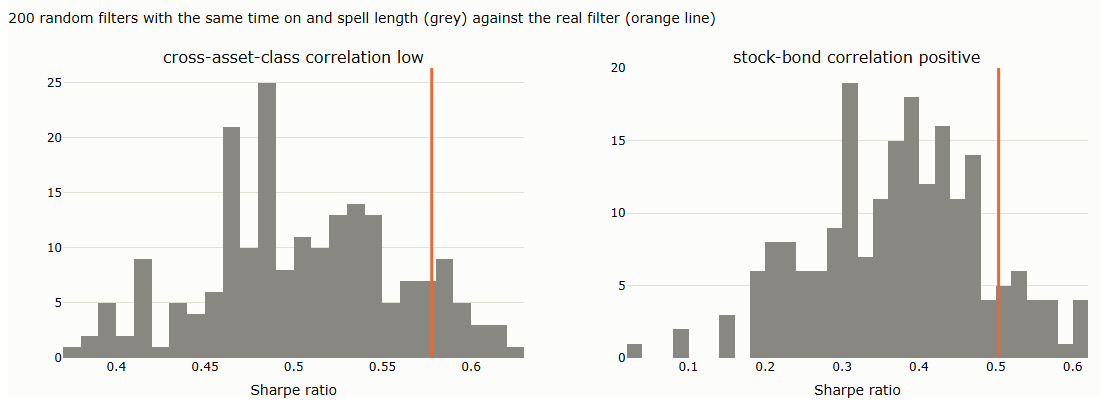

In [12]:
# chart G.6: the random-filter benchmark
fig = make_subplots(rows=1, cols=2, subplot_titles=list(rand_dist))
for j, (name, sims) in enumerate(rand_dist.items(), start=1):
    fig.add_histogram(x=sims, nbinsx=30, marker_color=MUTED, showlegend=False, row=1, col=j)
    fig.add_vline(x=rand_rows[name]["real filter Sharpe"], line=dict(color=SERIES[1], width=3), row=1, col=j)
fig.update_layout(title="200 random filters with the same time on and spell length (grey) against the real filter (orange line)",
                  height=420, width=1100, margin=dict(t=90))
fig.update_xaxes(title_text="Sharpe ratio")
save_figure(fig, "08_06_random_filter", FIG)
fig

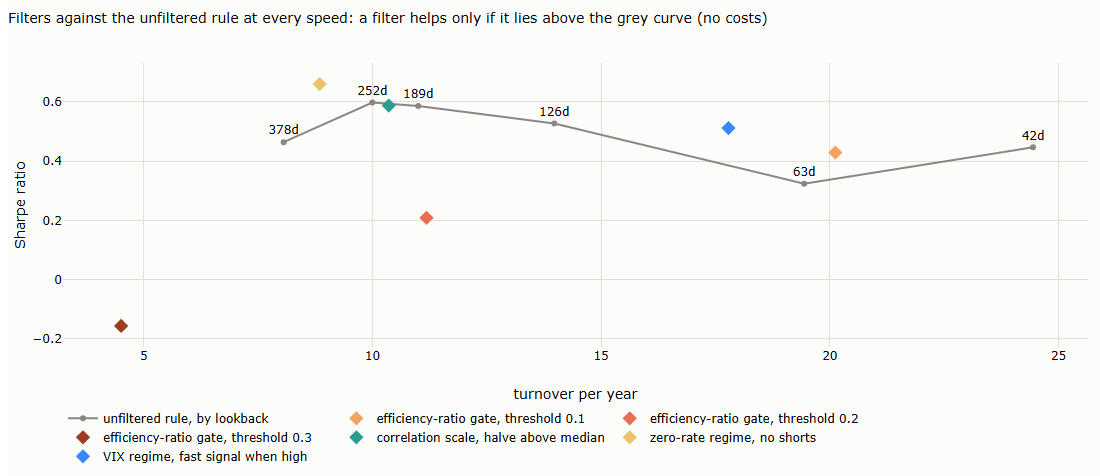

In [13]:
fig = go.Figure()
fig.add_scatter(x=cs["turnover per year"], y=cs["Sharpe, no costs"], mode="lines+markers+text", name="unfiltered rule, by lookback",
                text=[f"{n}d" for n in cs.index], textposition="top center", line=dict(color=MUTED, width=2))
for j, k in enumerate([k for k in table.index if k != "unfiltered 12-month rule"]):
    fig.add_scatter(x=[table.loc[k, "turnover per year"]], y=[table.loc[k, "Sharpe, no costs"]], mode="markers", name=k,
                    marker=dict(size=11, color=["#f4a261", "#e76f51", "#9c3d1f", "#2a9d8f", "#e9c46a", "#3a86ff"][j], symbol="diamond"))
fig.update_layout(title="Filters against the unfiltered rule at every speed: a filter helps only if it lies above the grey curve (no costs)",
                  xaxis_title="turnover per year", yaxis_title="Sharpe ratio", height=500, width=1100, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "08_01_filters_vs_curve", FIG)
fig

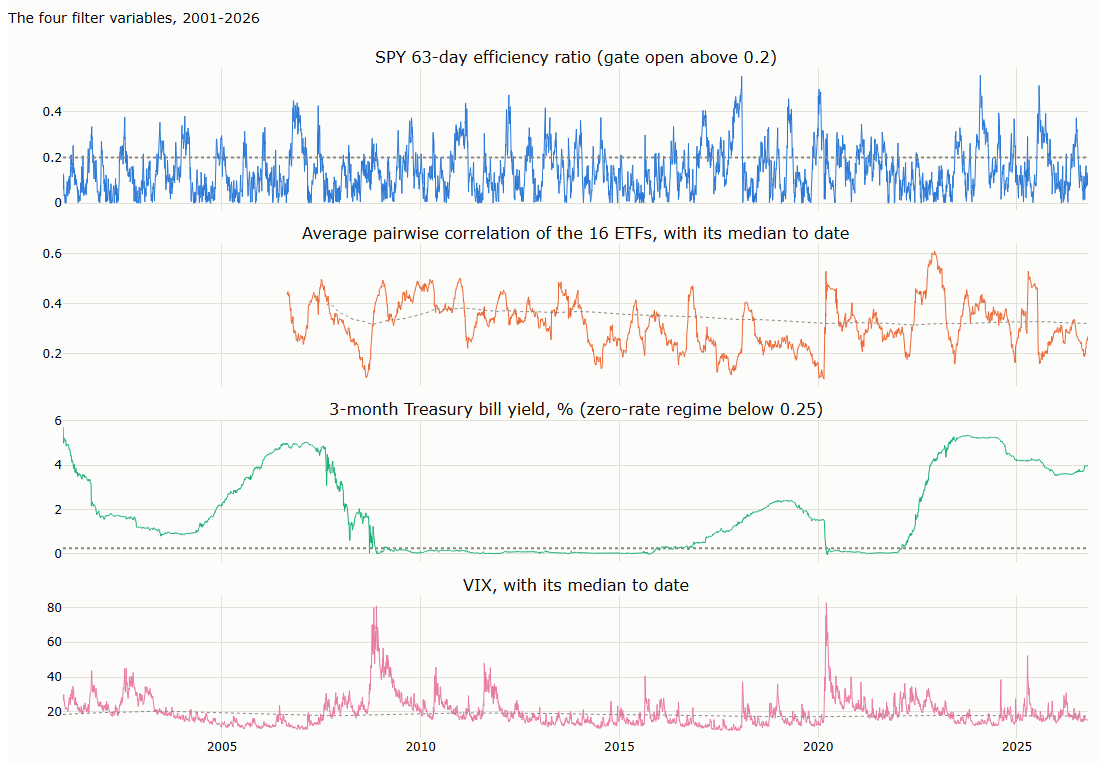

In [14]:
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.05,
                    subplot_titles=("SPY 63-day efficiency ratio (gate open above 0.2)", "Average pairwise correlation of the 16 ETFs, with its median to date",
                                    "3-month Treasury bill yield, % (zero-rate regime below 0.25)", "VIX, with its median to date"))
s_ = slice(START, None)
fig.add_scatter(x=er["SPY"].loc[s_].index, y=er["SPY"].loc[s_], mode="lines", line=dict(width=1, color=SERIES[0]), showlegend=False, row=1, col=1)
fig.add_hline(y=0.2, line=dict(color=MUTED, dash="dot"), row=1, col=1)
fig.add_scatter(x=avg_rho.loc[s_].index, y=avg_rho.loc[s_], mode="lines", line=dict(width=1, color=SERIES[1]), showlegend=False, row=2, col=1)
fig.add_scatter(x=rho_med.loc[s_].index, y=rho_med.loc[s_], mode="lines", line=dict(width=1, color=MUTED, dash="dot"), showlegend=False, row=2, col=1)
fig.add_scatter(x=tbill.loc[s_].index, y=tbill.loc[s_], mode="lines", line=dict(width=1, color=SERIES[2]), showlegend=False, row=3, col=1)
fig.add_hline(y=0.25, line=dict(color=MUTED, dash="dot"), row=3, col=1)
fig.add_scatter(x=vix.loc[s_].index, y=vix.loc[s_], mode="lines", line=dict(width=1, color=SERIES[3]), showlegend=False, row=4, col=1)
fig.add_scatter(x=vix_med.loc[s_].index, y=vix_med.loc[s_], mode="lines", line=dict(width=1, color=MUTED, dash="dot"), showlegend=False, row=4, col=1)
fig.update_layout(title="The four filter variables, 2001-2026", height=800, width=1100, margin=dict(t=90))
save_figure(fig, "08_02_filter_variables", FIG)
fig